# Phase 4 · The five learners

**Project 1 · FAA · breast_cancer (classification)**

**What this notebook does:** it presents the five learners, one per Domingos class, and checks that each one **works**. Hyperparameters are **not tuned** yet (Phase 5) and the learners are not really evaluated yet (Phases 5 and 6).

| Class | Learner | How it learns |
|---|---|---|
| Symbolic | Decision tree | yes/no rules |
| Connectionist | Neural network (MLP) | weights adjusted with the error |
| Evolutionary | Evolved linear model (DE) | a population that mutates and is selected |
| Bayesian | Gaussian Naive Bayes | Bayes' rule |
| Analogizer | SVM with RBF kernel | similarity to known cases |

**Requires** `utils_python.py` (functions from Phase 3) in the same folder.

### Cell 1: import the libraries

We import the libraries. The models come from scikit-learn, except the evolution, which uses **pyBlindOpt** (the course's evolutionary library).

In [1]:
import numpy as np  # numpy: numerical computing with arrays
import matplotlib.pyplot as plt  # matplotlib: draws the plots
import pyBlindOpt as pbo  # pyBlindOpt: evolutionary algorithms from the course
from sklearn.base import BaseEstimator, ClassifierMixin  # base classes to build our own model
from sklearn.calibration import CalibratedClassifierCV  # turns the SVM output into probabilities
from sklearn.metrics import matthews_corrcoef  # MCC
from sklearn.naive_bayes import GaussianNB  # Bayesian learner
from sklearn.neural_network import MLPClassifier  # connectionist learner
from sklearn.pipeline import Pipeline  # chains preprocessing + model
from sklearn.preprocessing import FunctionTransformer, StandardScaler  # preprocessing transformations
from sklearn.svm import SVC  # analogizer learner
from sklearn.tree import DecisionTreeClassifier, plot_tree  # symbolic learner and its drawing
from utils_python import load_data, compute_metrics  # functions from Phase 3

### Cell 2: load the data (only the training set is used in this phase)

We load the data with the Phase 3 function. In this phase only the **training set** is used; the test set stays set aside.

In [2]:
X_train, X_test, y_train, y_test, columns, path = load_data()  # same 455/114 split as always
figures_dir = path.parent.parent / "figures" / "04_models"  # folder for this phase's plots
figures_dir.mkdir(parents=True, exist_ok=True)  # create it if it does not exist
print("Train:", X_train.shape, "| the test set (", X_test.shape[0], "rows) is not touched")  # reminder

Train: (455, 30) | the test set ( 114 rows) is not touched


### Cell 3: one common mould for the five learners (saved in models_python.py)

**A common mould.** Each learner will be a `Pipeline` with three steps: `log1p` (switched off for now), `scaling` (only if the learner needs it) and `model`. This way the five are used in the same way (`fit`, `predict_proba`) and the preprocessing stays inside each fold, with no data leakage.

In Phase 5, the hyperparameter search will decide whether `log1p` is switched on.

In [3]:
def build(scale, model):  # preprocessing + model in a single object (no data leakage)
    scaling = StandardScaler() if scale else "passthrough"  # standardize only if the learner needs it
    return Pipeline([("log1p", "passthrough"), ("scaling", scaling), ("model", model)])  # log1p switched off by default; Phase 5 decides whether to switch it on

LOG1P = FunctionTransformer(np.log1p)  # log(1 + x) transformation, to be switched on in Phase 5
LOG_OPTIONS = ["passthrough", LOG1P]  # two options: untransformed or with log1p

### Cell 4: SYMBOLIC learner · decision tree

## 1) Symbolic · Decision tree

**Idea:** the model learns **yes/no rules** ("is `worst_perimeter` ≤ 112.8?"). At each node it chooses the question that best separates benign from malignant.

**Why it is symbolic:** its result is a set of rules a person can read. *A caveat we declare:* CART builds the rules greedily (node by node), not by strict "inverse deduction"; we place it on the border of the class.

Here we train a small tree just to **see** it.

Training MCC (just a check): 0.929


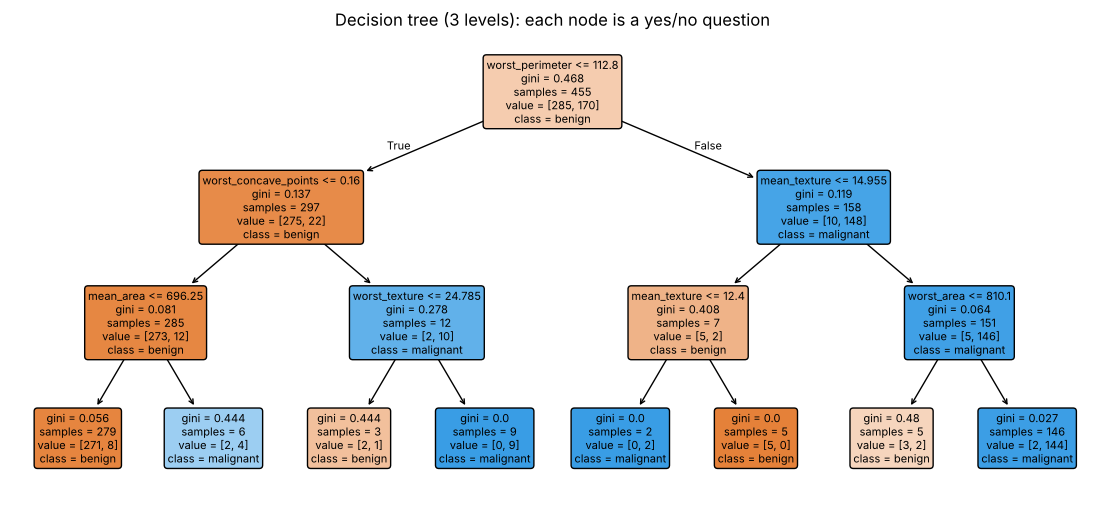

In [4]:
tree = build(False, DecisionTreeClassifier(max_depth=3, random_state=42))  # small tree (3 levels); needs no scaling
tree.fit(X_train, y_train)  # learns the rules from the training set
print("Training MCC (just a check):", round(matthews_corrcoef(y_train, tree.predict(X_train)), 3))  # check that it learns
plt.figure(figsize=(14, 6))  # large figure
plot_tree(tree.named_steps["model"], feature_names=columns, class_names=["benign", "malignant"], filled=True, rounded=True, fontsize=8)  # draw the rules
plt.title("Decision tree (3 levels): each node is a yes/no question")  # title
plt.savefig(figures_dir / "01_tree.png", bbox_inches="tight")  # save the image
plt.show()  # show it

**What we see:** the first question is `worst_perimeter` ≤ 112.8, which separates 297 tumours (almost all benign) from 158 (almost all malignant). With only 3 levels the training MCC is already 0.929. **Advantage:** a doctor could read it.

### Cell 5: CONNECTIONIST learner · neural network (MLP)

## 2) Connectionist · Neural network (MLP)

**Idea:** connected neurons with **weights** that are adjusted to reduce the error. Gradients are computed with **backpropagation** and used by the L-BFGS optimizer. It needs standardized data.

The `alpha` parameter penalizes large weights (regularization) and helps with collinearity.

In [5]:
mlp = build(True, MLPClassifier(hidden_layer_sizes=(8,), alpha=1.0, solver="lbfgs", max_iter=1000, random_state=42))  # 8 hidden neurons, regularization alpha=1
mlp.fit(X_train, y_train)  # adjusts the weights by minimizing the error (backpropagation + L-BFGS)
network = mlp.named_steps["model"]  # take the network out of the pipeline
n_weights = sum(w.size for w in network.coefs_) + sum(b.size for b in network.intercepts_)  # weights + biases of the whole network
print("Training MCC (just a check):", round(matthews_corrcoef(y_train, mlp.predict(X_train)), 3))  # check that it learns
print("Weight layers:", [w.shape for w in network.coefs_], "| total parameters:", n_weights)  # 30x8 and 8x1 weights + biases

Training MCC (just a check): 0.995
Weight layers: [(30, 8), (8, 1)] | total parameters: 257


**What we see:** training MCC 0.995 with 257 parameters for only 455 tumours: risk of overfitting, which is why the `alpha` regularization will be in the search.

### Cell 6: EVOLUTIONARY learner · building blocks (saved in models_python.py)

## 3) Evolutionary · Linear classifier with evolved weights

**Idea:** a tumour is malignant if `w·x + b > 0`. The 31 numbers (30 weights and a bias) are **not computed with a gradient**: a **population** of 40 candidates makes them evolve for 100 generations (differential evolution: mutate, cross over and keep the best). The fitness is the **MCC** directly.

**Why it is truly evolutionary:** evolution is the mechanism by which the model learns, not a hyperparameter adjustment. It makes sense because the MCC is a step function with no gradient.

**Warning:** its probabilities (sigmoid of the linear output) are **not calibrated**. This cell defines the model.

In [6]:
def population_mcc(Z, y, W):  # MCC of each individual in the population (each row of W is a classifier)
    pred = (Z @ W[:, :-1].T + W[:, -1]) > 0  # each column: predictions of one individual (w·x + b > 0)
    real = y.astype(bool)[:, None]  # true diagnosis as a True/False column
    tp, tn = (pred & real).sum(0), (~pred & ~real).sum(0)  # true positives and negatives of each individual
    fp, fn = (pred & ~real).sum(0), (~pred & real).sum(0)  # false positives and negatives of each individual
    den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)).astype(float)  # denominator of the MCC
    return np.where(den > 0, (tp * tn - fp * fn) / np.where(den > 0, den, 1.0), 0.0)  # MCC (0 if the denominator is 0)

class EvolutionaryClassifier(BaseEstimator, ClassifierMixin):  # our own model, compatible with scikit-learn
    def __init__(self, population=40, generations=100, bound=5.0, F=0.5, cr=0.7, seed=42):  # evolution parameters
        self.population, self.generations, self.bound = population, generations, bound  # size, number of generations and range of the weights
        self.F, self.cr, self.seed = F, cr, seed  # mutation strength, crossover probability and seed

    def fit(self, X, y):  # "learning" = making the population of weights evolve
        X, y = np.asarray(X, float), np.asarray(y)  # make sure we have numpy arrays
        self.classes_ = np.array([0, 1])  # the two classes
        bounds = np.array([[-self.bound, self.bound]] * (X.shape[1] + 1))  # each weight (30 weights + 1 bias) between -5 and 5
        objective = lambda W: -population_mcc(X, y, np.atleast_2d(W))  # DE minimizes, so we minimize -MCC
        evolution = pbo.DifferentialEvolution(objective, bounds, n_pop=self.population, n_iter=self.generations, F=self.F, cr=self.cr, seed=self.seed, debug=True)  # differential evolution
        best, score, _ = evolution.optimize()  # run the evolution and return the best individual
        self.coef_, self.intercept_ = best[:-1], best[-1]  # the 30 weights and the bias of the best individual
        self.train_mcc_ = -float(score)  # MCC of the best individual on the training set
        self.history_ = -evolution.history[:, 0]  # best MCC of each generation
        return self  # scikit-learn expects fit to return the model itself

    def decision_function(self, X):  # value w·x + b of each tumour
        return np.asarray(X, float) @ self.coef_ + self.intercept_  # dot product plus bias

    def predict_proba(self, X):  # "probability" of malignant (sigmoid; NOT calibrated)
        p = 1.0 / (1.0 + np.exp(-np.clip(self.decision_function(X), -50, 50)))  # sigmoid of the linear output
        return np.column_stack([1 - p, p])  # column 0 = benign, column 1 = malignant

    def predict(self, X):  # predicted class: malignant if w·x + b > 0
        return (self.decision_function(X) > 0).astype(int)  # 1 = malignant

### Cell 7: train the evolutionary learner and watch it converge

We train the evolutionary learner with seed 42 and look at how well it does and which weights are largest.

In [7]:
evolutionary = build(True, EvolutionaryClassifier(seed=42))  # the weights are bounded in [-5, 5], hence standardization first
evolutionary.fit(X_train, y_train)  # evolves 40 individuals for 100 generations
evo_model = evolutionary.named_steps["model"]  # take the evolutionary model out of the pipeline
print("Training MCC (just a check):", round(evo_model.train_mcc_, 3))  # check that it learns
print("MCC evaluations performed:", 40 * 101)  # 40 individuals x (100 generations + the initial one)
largest = np.argsort(np.abs(evo_model.coef_))[::-1][:3]  # the 3 features with the largest absolute weight
print("Features with the most weight:", [columns[i] for i in largest])  # which ones

Training MCC (just a check): 0.958
MCC evaluations performed: 4040
Features with the most weight: ['worst_area', 'mean_area', 'mean_smoothness']


**What we see:** training MCC 0.958 after 4,040 evaluations (40 individuals × 101 generations). The largest weights are on **size** variables (`worst_area`, `mean_area`), spread across redundant columns.

### Cell 8: the evolution with 5 different seeds

Evolution depends on chance. We repeat it with 5 seeds to see how much variation there is.

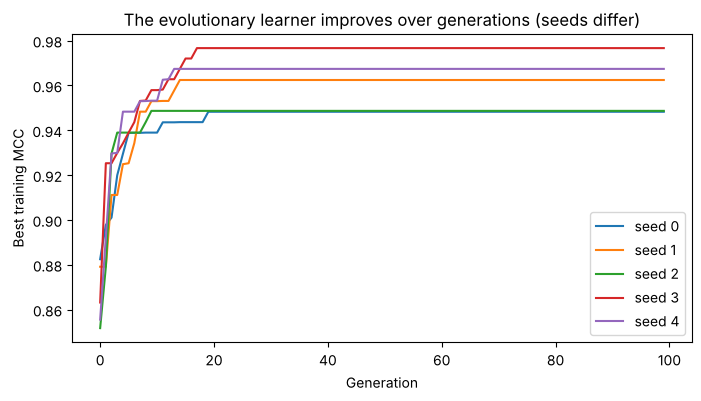

In [8]:
plt.figure(figsize=(8, 4))  # 8x4 figure
for seed in range(5):  # try 5 seeds
    seed_run = build(True, EvolutionaryClassifier(seed=seed)).fit(X_train, y_train)  # evolve with that seed
    plt.plot(seed_run.named_steps["model"].history_, label=f"seed {seed}")  # curve of best MCC per generation
plt.xlabel("Generation")  # horizontal axis
plt.ylabel("Best training MCC")  # vertical axis
plt.title("The evolutionary learner improves over generations (seeds differ)")  # title
plt.legend()  # legend
plt.savefig(figures_dir / "02_evolutionary_convergence.png", bbox_inches="tight")  # save
plt.show()  # show

**What we see:** all seeds improve quickly and stall around generation 20, but at different levels (from ~0.95 to ~0.98). This is **premature convergence**: the result depends on the seed. **Decision:** fixed budget (40 × 100), fixed seed, and it is not tuned by the search.

### Cell 9: BAYESIAN learner · Gaussian Naive Bayes

## 4) Bayesian · Gaussian Naive Bayes

**Idea:** it uses Bayes' rule: *probability of malignant given the evidence* ∝ *prior probability × probability of seeing those measurements in a malignant tumour*. For each feature it estimates a bell curve (mean and variance) per class.

**"Naive":** it assumes the 30 features are independent of each other. We saw in Phase 2 that they **are not** (21 pairs with |r| > 0.9). That is our overconfidence hypothesis.

In [9]:
bayes = build(False, GaussianNB())  # needs no scaling: it computes its own mean and variance per class
bayes.fit(X_train, y_train)  # "learns" by computing means and variances of each feature in each class
print("Training MCC (just a check):", round(matthews_corrcoef(y_train, bayes.predict(X_train)), 3))  # check that it learns
nb = bayes.named_steps["model"]  # take the model out of the pipeline
print("Prior probability (benign, malignant):", nb.class_prior_.round(3))  # 62.6% and 37.4%
j = columns.index("mean_area")  # example with mean_area
print(f"mean_area mean for benign: {nb.theta_[0, j]:.0f} | for malignant: {nb.theta_[1, j]:.0f}")  # learned means

Training MCC (just a check): 0.877
Prior probability (benign, malignant): [0.626 0.374]
mean_area mean for benign: 464 | for malignant: 988


**What we see:** prior 62.6% benign / 37.4% malignant; `mean_area` averages 464 in benign and 988 in malignant tumours. Training MCC 0.877, the lowest of the five (consistent with the hypothesis, although it is training only).

### Cell 10: ANALOGIZER learner · SVM with a kernel

## 5) Analogizer · SVM with a kernel

**Idea:** a new tumour is classified by its **similarity** to known tumours. The SVM keeps only the "borderline" cases (**support vectors**) and compares with them through an RBF kernel.

The SVM does not give probabilities by itself; we use **Platt calibration** (a sigmoid fitted to its output) to obtain them.

In [10]:
base_svm = SVC(kernel="rbf", C=10.0, gamma=0.01, random_state=42)  # SVM with RBF kernel (measures similarity between tumours)
svm = build(True, CalibratedClassifierCV(base_svm, method="sigmoid", ensemble=False, cv=3))  # Platt calibration: turns the output into a probability
svm.fit(X_train, y_train)  # trains the SVM and the calibration
svm_only = build(True, SVC(kernel="rbf", C=10.0, gamma=0.01, random_state=42)).fit(X_train, y_train)  # uncalibrated version, to count support vectors
print("Training MCC (just a check):", round(matthews_corrcoef(y_train, svm.predict(X_train)), 3))  # check that it learns
print("Support vectors ('reference' tumours):", int(svm_only.named_steps["model"].n_support_.sum()), "of", len(y_train))  # the SVM decides by similarity to them

Training MCC (just a check): 0.972
Support vectors ('reference' tumours): 56 of 455


**What we see:** the SVM uses only 56 of 455 tumours as references (12%) and reaches a training MCC of 0.972.

### Cell 11: the five learners and their search spaces (saved in models_python.py)

**Search spaces** that Phase 5 will use. Here they are only *defined* (nothing is tuned). This cell is saved to `models_python.py` so it can be reused.

In [11]:
learners = {  # dictionary: key -> (class, untrained pipeline, hyperparameter grid for Phase 5)
    "tree": ("Symbolic", build(False, DecisionTreeClassifier(random_state=42)),
             {"model__criterion": ["gini", "entropy"], "model__max_depth": [2, 3, 4, 5, 6, None], "model__min_samples_leaf": [1, 2, 5, 10]}),  # the tree does not use log1p
    "mlp": ("Connectionist", build(True, MLPClassifier(solver="lbfgs", max_iter=1000, random_state=42)),
            {"log1p": LOG_OPTIONS, "model__hidden_layer_sizes": [(4,), (8,), (16,), (32, 16)], "model__alpha": [1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0]}),  # alpha = regularization
    "evolutionary": ("Evolutionary", build(True, EvolutionaryClassifier()),
                     {"log1p": LOG_OPTIONS}),  # evolution is the learning: its budget is fixed and is not tuned
    "bayes": ("Bayesian", build(False, GaussianNB()),
              {"log1p": LOG_OPTIONS, "model__var_smoothing": [1e-11, 1e-9, 1e-7, 1e-5, 1e-3, 1e-1]}),  # variance smoothing
    "svm": ("Analogizer", build(True, CalibratedClassifierCV(SVC(kernel="rbf", random_state=42), method="sigmoid", ensemble=False, cv=3)),
            {"log1p": LOG_OPTIONS, "model__estimator__C": [0.1, 1.0, 10.0, 100.0, 1000.0], "model__estimator__gamma": [1e-4, 3e-4, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3]}),  # C and gamma of the SVM
}  # end of the dictionary
for key, (family, _, grid) in learners.items():  # loop over the five
    print(f"{family:13s} {key:12s} {int(np.prod([len(v) for v in grid.values()])):3d} configurations")  # how many combinations Phase 5 will try

Symbolic      tree          48 configurations
Connectionist mlp           48 configurations
Evolutionary  evolutionary   2 configurations
Bayesian      bayes         12 configurations
Analogizer    svm           80 configurations


**What we see:** 190 configurations in total (tree 48, MLP 48, evolutionary 2, Bayes 12, SVM 80). **Decision:** `log1p` is optional and decided by the inner validation, never by the test set; the tree does not use it.

### Cell 12: check that the five work the same way (same interface)

Final check: the five are trained and used with the same interface.

In [12]:
for key, (family, pipeline, _) in learners.items():  # loop over the five
    model = pipeline.fit(X_train, y_train)  # train with default parameters
    probabilities = model.predict_proba(X_train)[:, 1]  # probability of malignant
    m = compute_metrics(y_train, probabilities)  # metrics on the training set
    print(f"{family:13s} {key:12s} training MCC = {m['mcc']:.3f} | recall = {m['recall']:.3f}")  # one line per learner

Symbolic      tree         training MCC = 1.000 | recall = 1.000


Connectionist mlp          training MCC = 1.000 | recall = 1.000


Evolutionary  evolutionary training MCC = 0.958 | recall = 0.953
Bayesian      bayes        training MCC = 0.877 | recall = 0.900
Analogizer    svm          training MCC = 0.972 | recall = 0.971


**What we see (training set only):**

| Learner | Training MCC |
|---|---|
| Tree (no depth limit) | 1.000 |
| MLP (minimal regularization) | 1.000 |
| SVM | 0.972 |
| Evolutionary | 0.958 |
| Naive Bayes | 0.877 |

**Careful:** a 1.000 on the training set is **memorization**, not quality. The unlimited tree and the barely regularized MLP learn the 455 cases by heart. **These numbers cannot be used to compare learners**; the honest comparison is on validation (Phase 5) and test (Phase 6).

## Summary of the Phase 4 decisions

| Learner | Preprocessing | Search space (Phase 5) | Configurations |
|---|---|---|---|
| Tree | none | criterion, depth, minimum leaf size | 48 |
| MLP | optional `log1p` + standardization | `log1p`, network size, `alpha` | 48 |
| Evolutionary | optional `log1p` + standardization | only `log1p` (fixed budget 40 × 100) | 2 |
| Naive Bayes | optional `log1p` | `log1p`, `var_smoothing` | 12 |
| SVM + Platt | optional `log1p` + standardization | `log1p`, `C`, `gamma` | 80 |

**Points to justify in the README:** the tree is greedy (class border); the evolutionary learner is linear and what defines it is *how it learns*; its probabilities are **not calibrated**; the SVM needs Platt scaling to give probabilities.

**Limit:** the assignment mentions Keras/JAX; we use scikit-learn's `MLPClassifier`, which the assignment allows.

**Generated files:** `models_python.py` (the five learners and their grids, for Phases 5 and 6) and the plots in `figures/04_models/`.

**Next:** Phase 5 · Tuning with nested cross-validation.